In [1]:
from scipy import stats

data1 = [12, 14, 15, 13, 16, 14, 15]
data2 = [18, 20, 19, 21, 17, 22, 20]
data3 = [10, 11, 9, 12, 10, 11, 13]

# 1. Mann-Whitney U test (non-parametric alternative to independent t-test)
u_stat, p_val = stats.mannwhitneyu(data1, data2)

# 2. Wilcoxon signed-rank test (non-parametric alternative to paired t-test)
w_stat, p_val = stats.wilcoxon(data1, data2)

# 3. Kruskal-Wallis H-test (non-parametric alternative to one-way ANOVA)
h_stat, p_val = stats.kruskal(data1, data2, data3)

# 4. Friedman test (non-parametric repeated measures ANOVA)
f_stat, p_val = stats.friedmanchisquare(data1, data2, data3)

# 5. Kolmogorov-Smirnov test (compare two samples or one sample vs a distribution)
ks_stat, p_val = stats.ks_2samp(data1, data2)
ks_1samp, p_val = stats.kstest(data1, 'norm')

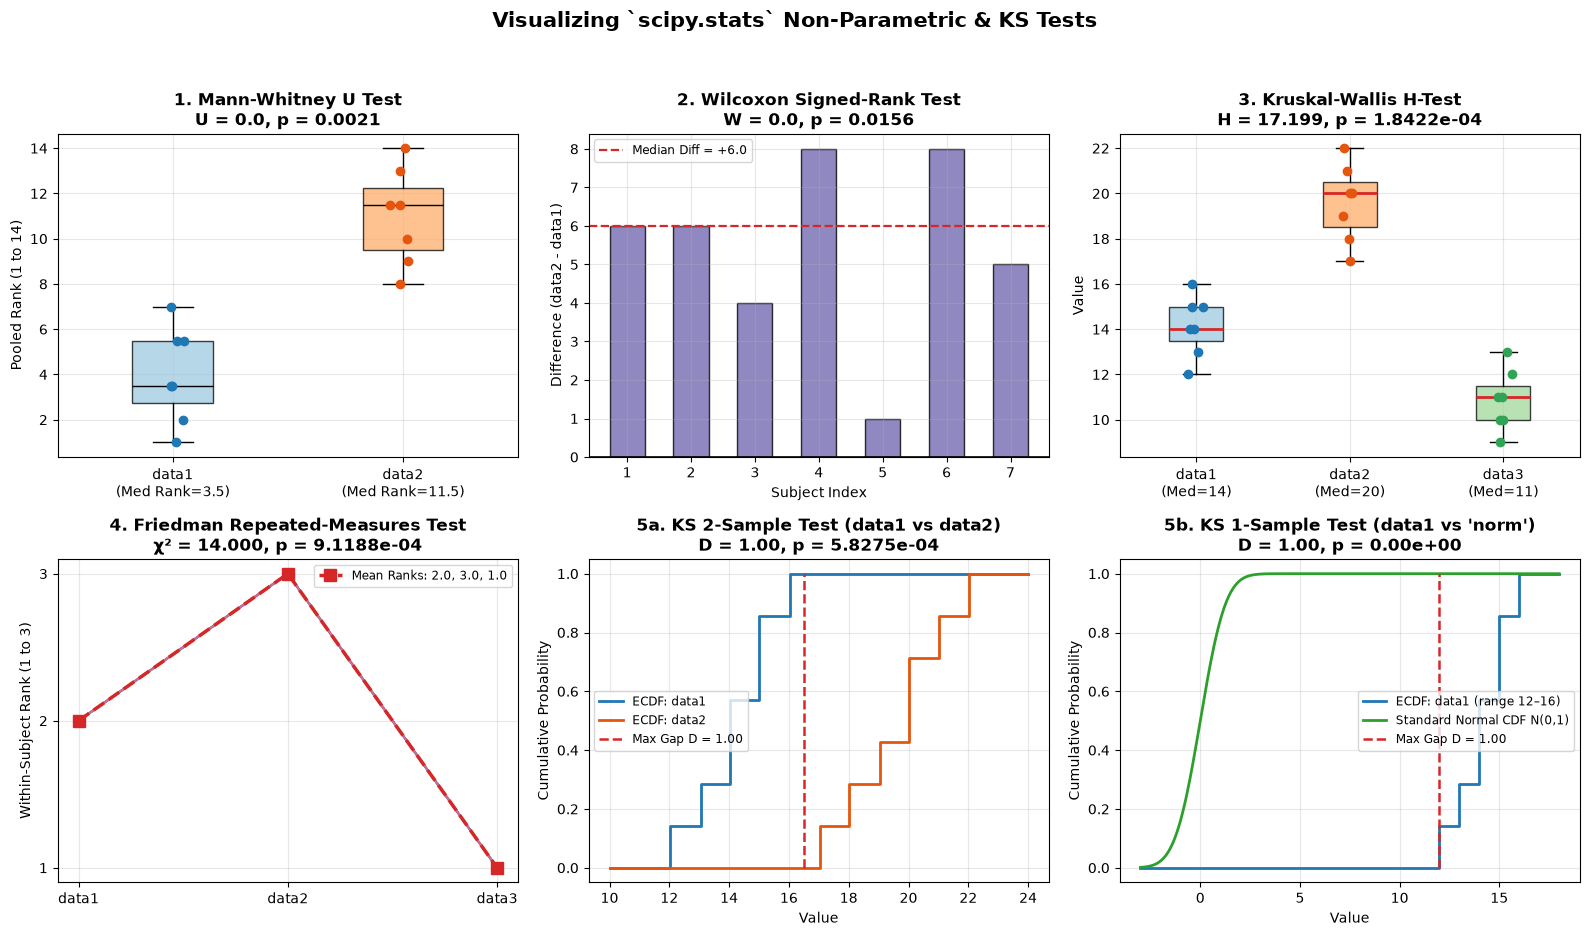

In [4]:
from scipy import stats

data1 = [12, 14, 15, 13, 16, 14, 15]
data2 = [18, 20, 19, 21, 17, 22, 20]
data3 = [10, 11, 9, 12, 10, 11, 13]

# 1. Mann-Whitney U test (non-parametric alternative to independent t-test)
u_stat, p_val = stats.mannwhitneyu(data1, data2)
u1, p1 = u_stat, p_val

# 2. Wilcoxon signed-rank test (non-parametric alternative to paired t-test)
w_stat, p_val = stats.wilcoxon(data1, data2)
w2, p2 = w_stat, p_val

# 3. Kruskal-Wallis H-test (non-parametric alternative to one-way ANOVA)
h_stat, p_val = stats.kruskal(data1, data2, data3)
h3, p3 = h_stat, p_val

# 4. Friedman test (non-parametric repeated measures ANOVA)
f_stat, p_val = stats.friedmanchisquare(data1, data2, data3)
f4, p4 = f_stat, p_val

# 5. Kolmogorov-Smirnov test (compare two samples or one sample vs a distribution)
ks_stat, p_val = stats.ks_2samp(data1, data2)
ks5_2, p5_2 = ks_stat, p_val
ks_1samp, p_val = stats.kstest(data1, 'norm')
ks5_1, p5_1 = ks_1samp, p_val

# --- Visualization of the outputs above ---
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
fig.suptitle("Visualizing `scipy.stats` Non-Parametric & KS Tests", fontsize=15, fontweight='bold')
np.random.seed(42)

# Panel 1: Mann-Whitney U test (Pooled ranks of data1 vs data2)
ax = axes[0, 0]
ranks_12 = stats.rankdata(np.concatenate([data1, data2]))
r1, r2 = ranks_12[:len(data1)], ranks_12[len(data1):]
bp1 = ax.boxplot([r1, r2], positions=[1, 2], widths=0.35, patch_artist=True, medianprops=dict(color='black'))
for patch, c in zip(bp1['boxes'], ['#9ecae1', '#fdae6b']):
    patch.set_facecolor(c)
    patch.set_alpha(0.75)
ax.scatter(np.random.normal(1, 0.03, len(r1)), r1, color='#1f77b4', zorder=4)
ax.scatter(np.random.normal(2, 0.03, len(r2)), r2, color='#e6550d', zorder=4)
ax.set_xticks([1, 2])
ax.set_xticklabels([f'data1\n(Med Rank={np.median(r1):.1f})', f'data2\n(Med Rank={np.median(r2):.1f})'])
ax.set_ylabel('Pooled Rank (1 to 14)')
ax.set_title(f'1. Mann-Whitney U Test\nU = {u1:.1f}, p = {p1:.4f}', fontweight='bold')
ax.grid(True, alpha=0.3)

# Panel 2: Wilcoxon signed-rank test (Paired differences data2 - data1)
ax = axes[0, 1]
diffs = np.array(data2) - np.array(data1)
subjects = np.arange(1, len(diffs) + 1)
ax.bar(subjects, diffs, color='#756bb1', alpha=0.8, edgecolor='black', width=0.55)
ax.axhline(0, color='black', lw=1.2)
ax.axhline(np.median(diffs), color='#d62728', linestyle='--', lw=1.6, label=f'Median Diff = +{np.median(diffs):.1f}')
ax.set_xticks(subjects)
ax.set_xlabel('Subject Index')
ax.set_ylabel('Difference (data2 - data1)')
ax.set_title(f'2. Wilcoxon Signed-Rank Test\nW = {w2:.1f}, p = {p2:.4f}', fontweight='bold')
ax.legend(loc='upper left', fontsize=8.5)
ax.grid(True, alpha=0.3)

# Panel 3: Kruskal-Wallis H-test (Group medians across 3 independent samples)
ax = axes[0, 2]
bp3 = ax.boxplot([data1, data2, data3], positions=[1, 2, 3], widths=0.35, patch_artist=True,
                 medianprops=dict(color='#d62728', lw=2))
for patch, c in zip(bp3['boxes'], ['#9ecae1', '#fdae6b', '#a1d99b']):
    patch.set_facecolor(c)
    patch.set_alpha(0.75)
for idx, (d, c) in enumerate(zip([data1, data2, data3], ['#1f77b4', '#e6550d', '#31a354']), start=1):
    ax.scatter(np.random.normal(idx, 0.03, len(d)), d, color=c, zorder=4)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels([f'data1\n(Med={np.median(data1):.0f})', f'data2\n(Med={np.median(data2):.0f})', f'data3\n(Med={np.median(data3):.0f})'])
ax.set_ylabel('Value')
ax.set_title(f'3. Kruskal-Wallis H-Test\nH = {h3:.3f}, p = {p3:.4e}', fontweight='bold')
ax.grid(True, alpha=0.3)

# Panel 4: Friedman test (Within-subject ranks across 3 conditions)
ax = axes[1, 0]
within_ranks = np.array([stats.rankdata(row) for row in np.column_stack([data1, data2, data3])])
for i in range(len(data1)):
    ax.plot([1, 2, 3], within_ranks[i], 'o-', alpha=0.65, lw=1.5)
mean_ranks = within_ranks.mean(axis=0)
ax.plot([1, 2, 3], mean_ranks, 's--', color='#d62728', lw=2.5, markersize=8,
        label=f'Mean Ranks: {mean_ranks[0]:.1f}, {mean_ranks[1]:.1f}, {mean_ranks[2]:.1f}')
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(['data1', 'data2', 'data3'])
ax.set_yticks([1, 2, 3])
ax.set_ylabel('Within-Subject Rank (1 to 3)')
ax.set_title(f'4. Friedman Repeated-Measures Test\nχ² = {f4:.3f}, p = {p4:.4e}', fontweight='bold')
ax.legend(loc='upper right', fontsize=8.5)
ax.grid(True, alpha=0.3)

# Panel 5: KS 2-sample test (Empirical CDFs of data1 vs data2)
ax = axes[1, 1]
x_grid = np.linspace(10, 24, 300)
ecdf1 = np.searchsorted(np.sort(data1), x_grid, side='right') / len(data1)
ecdf2 = np.searchsorted(np.sort(data2), x_grid, side='right') / len(data2)
ax.step(x_grid, ecdf1, where='post', color='#1f77b4', lw=2, label='ECDF: data1')
ax.step(x_grid, ecdf2, where='post', color='#e6550d', lw=2, label='ECDF: data2')
ax.vlines(16.5, 0, 1, color='#d62728', linestyle='--', lw=1.8, label=f'Max Gap D = {ks5_2:.2f}')
ax.set_xlabel('Value')
ax.set_ylabel('Cumulative Probability')
ax.set_title(f'5a. KS 2-Sample Test (data1 vs data2)\nD = {ks5_2:.2f}, p = {p5_2:.4e}', fontweight='bold')
ax.legend(loc='center left', fontsize=8.5)
ax.grid(True, alpha=0.3)

# Panel 6: KS 1-sample test (Empirical CDF of data1 vs standard N(0,1))
ax = axes[1, 2]
x_grid1 = np.linspace(-3, 18, 400)
ecdf1_wide = np.searchsorted(np.sort(data1), x_grid1, side='right') / len(data1)
ax.step(x_grid1, ecdf1_wide, where='post', color='#1f77b4', lw=2, label='ECDF: data1 (range 12–16)')
ax.plot(x_grid1, stats.norm.cdf(x_grid1), color='#2ca02c', lw=2, label='Standard Normal CDF N(0,1)')
ax.vlines(12, 0, 1, color='#d62728', linestyle='--', lw=1.8, label=f'Max Gap D = {ks5_1:.2f}')
ax.set_xlabel('Value')
ax.set_ylabel('Cumulative Probability')
ax.set_title(f"5b. KS 1-Sample Test (data1 vs 'norm')\nD = {ks5_1:.2f}, p = {p5_1:.2e}", fontweight='bold')
ax.legend(loc='center right', fontsize=8.5)
ax.grid(True, alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()